<a href="https://colab.research.google.com/github/Statistics-Inho/Big-data-programming/blob/main/week05_5874941_%EC%B5%9C%EC%9D%B8%ED%98%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5주차 과제
빅데이터프로그래밍 · 통계학과

**이름:** 최인호
**학번:** 5874941

## 제출 방법
모든 셀을 실행해 출력이 보이는 상태로 저장한 뒤 `week05_학번_이름.ipynb` 로 제출합니다.


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(0)


## 문제 1. 사용자 정의 Dataset 작성 (40점)
아래 조건으로 Dataset 클래스를 작성하세요.

- 데이터 개수는 30개, 입력 특성은 4개
- `__init__` `__len__` `__getitem__` 세 메서드를 모두 구현
- 각 메서드가 하는 일을 주석으로 한 줄씩 설명


In [2]:
# 답안
import torch
from torch.utils.data import Dataset


class CustomDataset(Dataset):

    def __init__(self):
        # 30개의 샘플과 4개의 입력 특성을 가지는 가상 데이터를 생성하고 초기화합니다.
        self.data = torch.randn(30, 4)

    def __len__(self):
        # 데이터셋의 전체 샘플 개수(30개)를 반환합니다.
        return len(self.data)

    def __getitem__(self, idx):
        # 지정한 인덱스(idx)에 해당하는 하나의 데이터 샘플을 반환합니다.
        return self.data[idx]

## 문제 2. DataLoader로 batch 출력 (30점)
문제 1의 Dataset을 DataLoader에 넣고 아래를 출력하세요.

- batch 개수
- 각 batch의 입력 shape과 정답 shape
- 마지막 batch의 크기가 다른 이유 (batch size를 7로 두고 확인)


In [3]:
# 답안
import torch
from torch.utils.data import DataLoader, Dataset


# 문제 1의 Dataset 정의
class CustomDataset(Dataset):

    def __init__(self):
        # 30개의 샘플과 4개의 입력 특성, 그리고 가상의 정답 데이터를 생성하고 초기화합니다.
        self.x_data = torch.randn(30, 4)
        self.y_data = torch.randint(0, 2, (30,))

    def __len__(self):
        # 데이터셋의 전체 샘플 개수(30개)를 반환합니다.
        return len(self.x_data)

    def __getitem__(self, idx):
        # 지정한 인덱스(idx)에 해당하는 입력 데이터와 정답 데이터를 반환합니다.
        return self.x_data[idx], self.y_data[idx]


# Dataset 인스턴스 생성 및 DataLoader 설정 (batch_size=7)
dataset = CustomDataset()
dataloader = DataLoader(dataset, batch_size=7, shuffle=False)

# 1. 전체 batch 개수 출력
print(f"전체 batch 개수: {len(dataloader)}")
print("-" * 40)

# 2. 각 batch의 입력 shape과 정답 shape 출력
for batch_idx, (inputs, targets) in enumerate(dataloader):
    print(
        f"Batch {batch_idx + 1} - 입력 shape: {inputs.shape}, 정답 shape: {targets.shape}"
    )

전체 batch 개수: 5
----------------------------------------
Batch 1 - 입력 shape: torch.Size([7, 4]), 정답 shape: torch.Size([7])
Batch 2 - 입력 shape: torch.Size([7, 4]), 정답 shape: torch.Size([7])
Batch 3 - 입력 shape: torch.Size([7, 4]), 정답 shape: torch.Size([7])
Batch 4 - 입력 shape: torch.Size([7, 4]), 정답 shape: torch.Size([7])
Batch 5 - 입력 shape: torch.Size([2, 4]), 정답 shape: torch.Size([2])


## 문제 3. batch shape 설명 (10점)
문제 2의 출력에서 batch shape이 왜 그렇게 나오는지 설명하세요.
`(batch_size, 특성 수)` 의 각 숫자가 무엇을 뜻하는지 적으면 됩니다.


**답:**배치 사이즈 (7,4)에서 7은 한번에 묶어서 모델에 전달하는 데이터의 개수이며 4는 개별데이터 샘플 1개가 가지고 있는 입력 특성의 개수이다.


## 문제 4. 학습 루프 작성 (20점)
문제 1의 Dataset으로 아래를 수행하세요.

1. `nn.Linear` 모델 하나를 만든다
2. 다섯 단계(예측 → 손실 → 초기화 → 역전파 → 수정)로 학습 루프를 작성한다
3. epoch마다 평균 손실을 출력해 손실이 내려가는지 확인한다


In [6]:
# 답안
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset


# 1. Dataset 및 DataLoader 준비
class CustomDataset(Dataset):

    def __init__(self):
        # 학습 규칙성 확인을 위해 고정된 선형 관계(y = x1 + x2 + x3 + x4 + noise) 데이터 생성
        torch.manual_seed(42)
        self.x_data = torch.randn(30, 4)
        self.y_data = self.x_data.sum(dim=1, keepdim=True) + torch.randn(
            30, 1
        ) * 0.1

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        return self.x_data[idx], self.y_data[idx]


dataset = CustomDataset()
dataloader = DataLoader(dataset, batch_size=7, shuffle=True)

# 2. nn.Linear 모델, 손실함수, 옵티마이저 정의
model = nn.Linear(in_features=4, out_features=1)  # 입력 특성 4개 -> 출력 1개
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# 3. 학습 루프 수행 (20 Epochs)
num_epochs = 20

for epoch in range(1, num_epochs + 1):
    total_loss = 0.0

    for inputs, targets in dataloader:
        # Step 1. 예측 (Forward)
        outputs = model(inputs)

        # Step 2. 손실 계산 (Loss)
        loss = criterion(outputs, targets)

        # Step 3. 변화도 초기화 (Zero Grad)
        optimizer.zero_grad()

        # Step 4. 역전파 (Backward)
        loss.backward()

        # Step 5. 가중치 수정 (Optimizer Step)
        optimizer.step()

        total_loss += loss.item() * len(inputs)

    # Epoch별 평균 손실 계산 및 출력
    avg_loss = total_loss / len(dataset)
    print(f"Epoch [{epoch:2d}/{num_epochs}] - 평균 손실(Loss): {avg_loss:.4f}")

Epoch [ 1/20] - 평균 손실(Loss): 2.6816
Epoch [ 2/20] - 평균 손실(Loss): 2.2609
Epoch [ 3/20] - 평균 손실(Loss): 1.9203
Epoch [ 4/20] - 평균 손실(Loss): 1.6138
Epoch [ 5/20] - 평균 손실(Loss): 1.3811
Epoch [ 6/20] - 평균 손실(Loss): 1.1886
Epoch [ 7/20] - 평균 손실(Loss): 0.9486
Epoch [ 8/20] - 평균 손실(Loss): 0.8030
Epoch [ 9/20] - 평균 손실(Loss): 0.6553
Epoch [10/20] - 평균 손실(Loss): 0.5516
Epoch [11/20] - 평균 손실(Loss): 0.4761
Epoch [12/20] - 평균 손실(Loss): 0.4036
Epoch [13/20] - 평균 손실(Loss): 0.3477
Epoch [14/20] - 평균 손실(Loss): 0.2812
Epoch [15/20] - 평균 손실(Loss): 0.2275
Epoch [16/20] - 평균 손실(Loss): 0.2020
Epoch [17/20] - 평균 손실(Loss): 0.1762
Epoch [18/20] - 평균 손실(Loss): 0.1501
Epoch [19/20] - 평균 손실(Loss): 0.1279
Epoch [20/20] - 평균 손실(Loss): 0.1134


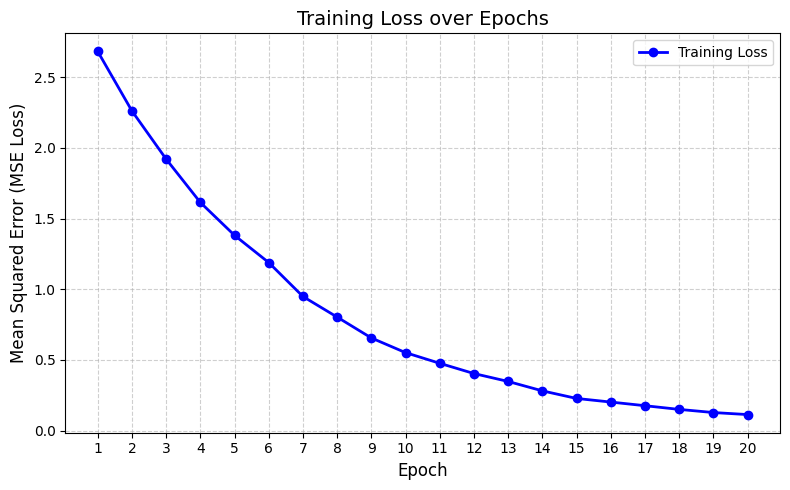

In [5]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset


# 1. Dataset 및 DataLoader 준비
class CustomDataset(Dataset):

    def __init__(self):
        torch.manual_seed(42)
        self.x_data = torch.randn(30, 4)
        self.y_data = self.x_data.sum(dim=1, keepdim=True) + torch.randn(
            30, 1
        ) * 0.1

    def __len__(self):
        return len(self.x_data)

    def __getitem__(self, idx):
        return self.x_data[idx], self.y_data[idx]


dataset = CustomDataset()
dataloader = DataLoader(dataset, batch_size=7, shuffle=True)

# 2. 모델, 손실함수, 옵티마이저 설정
model = nn.Linear(in_features=4, out_features=1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# 3. Epoch별 손실 기록을 위한 리스트
num_epochs = 20
loss_history = []

# 4. 학습 루프
for epoch in range(1, num_epochs + 1):
    total_loss = 0.0

    for inputs, targets in dataloader:
        outputs = model(inputs)
        loss = criterion(outputs, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(inputs)

    avg_loss = total_loss / len(dataset)
    loss_history.append(avg_loss)  # 손실값 기록

# 5. 손실 감소 그래프 시각화
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, num_epochs + 1),
    loss_history,
    marker="o",
    color="b",
    linewidth=2,
    label="Training Loss",
)
plt.title("Training Loss over Epochs", fontsize=14)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Mean Squared Error (MSE Loss)", fontsize=12)
plt.xticks(range(1, num_epochs + 1))
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()